In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, precision_score, recall_score
from sklearn.model_selection import RandomizedSearchCV
from preprocessing import dropper, ordinalencoder, OHEEncoder

In [2]:
df=pd.read_csv("train.csv")
df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

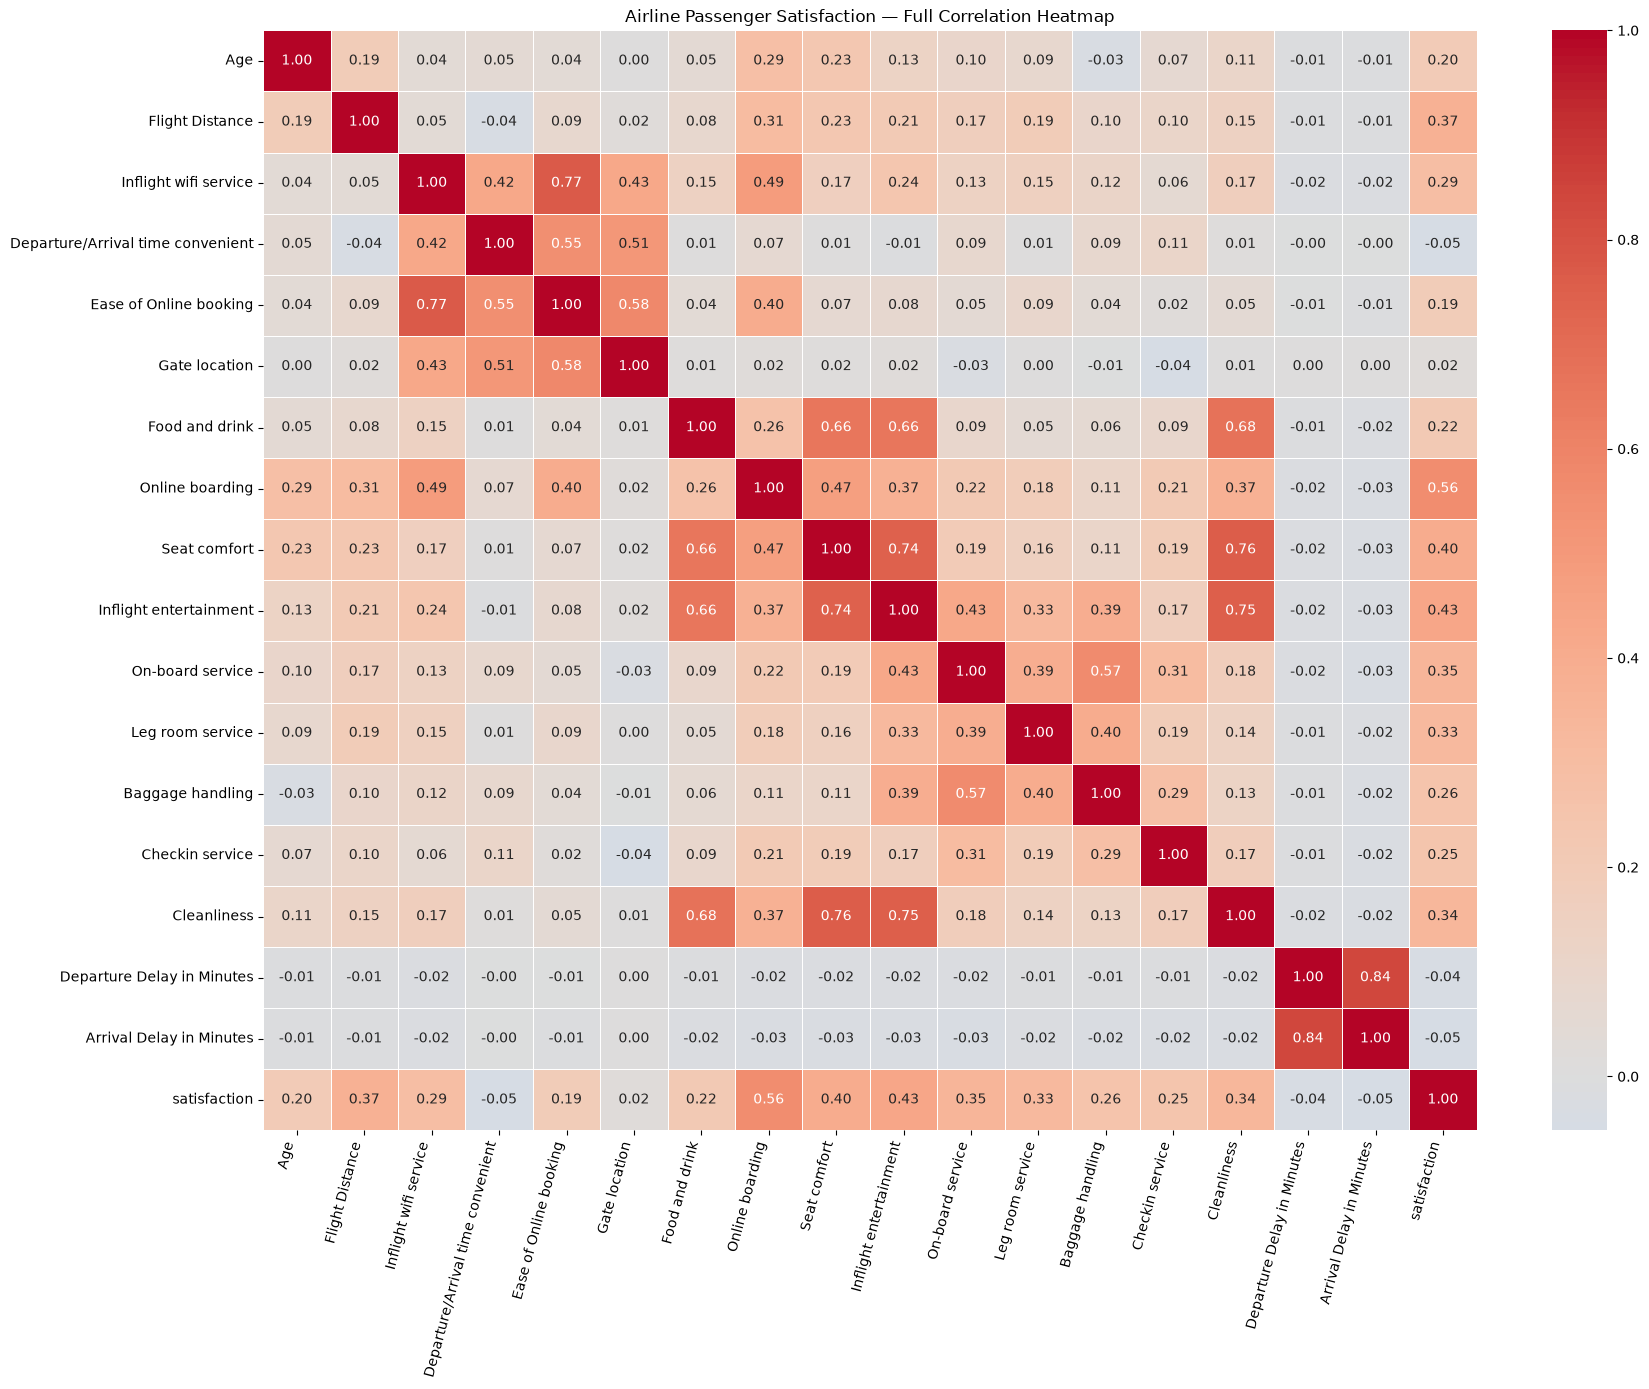

In [4]:
num_df = df.select_dtypes(include=["number"])
num_df = num_df.drop(columns=["id"], errors="ignore")
num_df["satisfaction"] = df["satisfaction"].astype(int)
plt.figure(figsize=(18, 14))
sns.heatmap(
    num_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Airline Passenger Satisfaction — Full Correlation Heatmap")
plt.xticks(rotation=75, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
df["satisfaction"] = df["satisfaction"].astype(int)

In [6]:
x = df.drop(columns=["satisfaction"])
y = df["satisfaction"]
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
print(y.value_counts())
print(y_train.head())

satisfaction
0    389296
1    310339
Name: count, dtype: int64
159366    1
659958    0
434666    0
427957    1
409049    0
Name: satisfaction, dtype: int64


MISSING

In [8]:
# cols = ["Arrival Delay in Minutes"]
# class NumericalImputer(BaseEstimator, TransformerMixin):
#     def __init__(self, strategy="median"):
#         self.strategy = strategy
#     def fit(self, X, y=None):
#         if self.strategy == "median":
#             self.fill_value_ = np.nanmedian(X, axis=0)
#         elif self.strategy == "mean":
#             self.fill_value_ = np.nanmean(X, axis=0)
#         else:
#             raise ValueError("Use 'mean' or 'median'")
#         return self
#     def transform(self, X):
#         X = np.asarray(X, dtype=float).copy()
#         missing_rows, missing_cols = np.where(np.isnan(X))
#         X[missing_rows, missing_cols] = self.fill_value_[missing_cols]
#         return X

DROPPER

In [9]:
# cols2=['id']
# class dropper(BaseEstimator,TransformerMixin):
#     def fit(self,x,y=None):
#         return self
#     def transform(self,x):
#         x=x.drop(cols2,axis=1)
#         return x

ADDING FEATURE

In [10]:
class AirlineFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.service_cols = [
            "Inflight wifi service",
            "Departure/Arrival time convenient",
            "Ease of Online booking",
            "Gate location",
            "Food and drink",
            "Online boarding",
            "Seat comfort",
            "Inflight entertainment",
            "On-board service",
            "Leg room service",
            "Baggage handling",
            "Checkin service",
            "Cleanliness"
        ]
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["Total_Delay"] = (
            X["Departure Delay in Minutes"]
            + X["Arrival Delay in Minutes"]
        )
        X["Average_Service_Rating"] = (
            X[self.service_cols].mean(axis=1)
        )
        X["Service_Rating_Count"] = (
            (X[self.service_cols] <= 2).sum(axis=1)
        )
        return X

In [11]:
cat_cols=x_train.select_dtypes(include=['str']).columns.tolist()
for cols in cat_cols:
    print(f"\n{cols}")
    print(x_train[cols].value_counts(dropna=False).head(20))


Gender
Gender
Male      281255
Female    278453
Name: count, dtype: int64

Customer Type
Customer Type
Loyal Customer       461550
disloyal Customer     98158
Name: count, dtype: int64

Type of Travel
Type of Travel
Business travel    398234
Personal Travel    161474
Name: count, dtype: int64

Class
Class
Business    273767
Eco         261966
Eco Plus     23975
Name: count, dtype: int64


ORDINAL ENCODING

In [12]:
# cust_type_order=['disloyal Customer','Loyal Customer']
# travel_order=['Personal Travel','Business travel']
# class_order=['Eco','Eco Plus','Business']
# cols3=['Customer Type','Type of Travel','Class']
# class ordinalencoder(BaseEstimator, TransformerMixin):
#     def fit(self, x, y=None):
#         self.oe = OrdinalEncoder(
#             categories=[
#                 cust_type_order,
#                 travel_order,
#                 class_order
#             ]
#         )
#         self.oe.fit(x[cols3])
#         return self
#     def transform(self, x):
#         x[cols3] = self.oe.transform(x[cols3])
#         return x

ONE HOT ENCODING

In [13]:
# ohe_cols = ['Gender']
# class OHEEncoder(BaseEstimator, TransformerMixin):
#     def fit(self, x, y=None):
#         self.encoder = OneHotEncoder(
#             drop='first',
#             sparse_output=False,
#             handle_unknown='ignore'
#         )
#         self.encoder.fit(x[ohe_cols])
#         return self
#     def transform(self, x):
#         encoded = self.encoder.transform(x[ohe_cols])
#         encoded_df = pd.DataFrame(
#             encoded,
#             columns=self.encoder.get_feature_names_out(ohe_cols),
#             index=x.index
#         )
#         x = x.drop(ohe_cols, axis=1)
#         x = pd.concat([x, encoded_df], axis=1)
#         return x

array([[<Axes: title={'center': 'id'}>, <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Flight Distance'}>,
        <Axes: title={'center': 'Inflight wifi service'}>],
       [<Axes: title={'center': 'Departure/Arrival time convenient'}>,
        <Axes: title={'center': 'Ease of Online booking'}>,
        <Axes: title={'center': 'Gate location'}>,
        <Axes: title={'center': 'Food and drink'}>],
       [<Axes: title={'center': 'Online boarding'}>,
        <Axes: title={'center': 'Seat comfort'}>,
        <Axes: title={'center': 'Inflight entertainment'}>,
        <Axes: title={'center': 'On-board service'}>],
       [<Axes: title={'center': 'Leg room service'}>,
        <Axes: title={'center': 'Baggage handling'}>,
        <Axes: title={'center': 'Checkin service'}>,
        <Axes: title={'center': 'Cleanliness'}>],
       [<Axes: title={'center': 'Departure Delay in Minutes'}>,
        <Axes: title={'center': 'Arrival Delay in Minutes'}>, <Axes: >,
        <Axes:

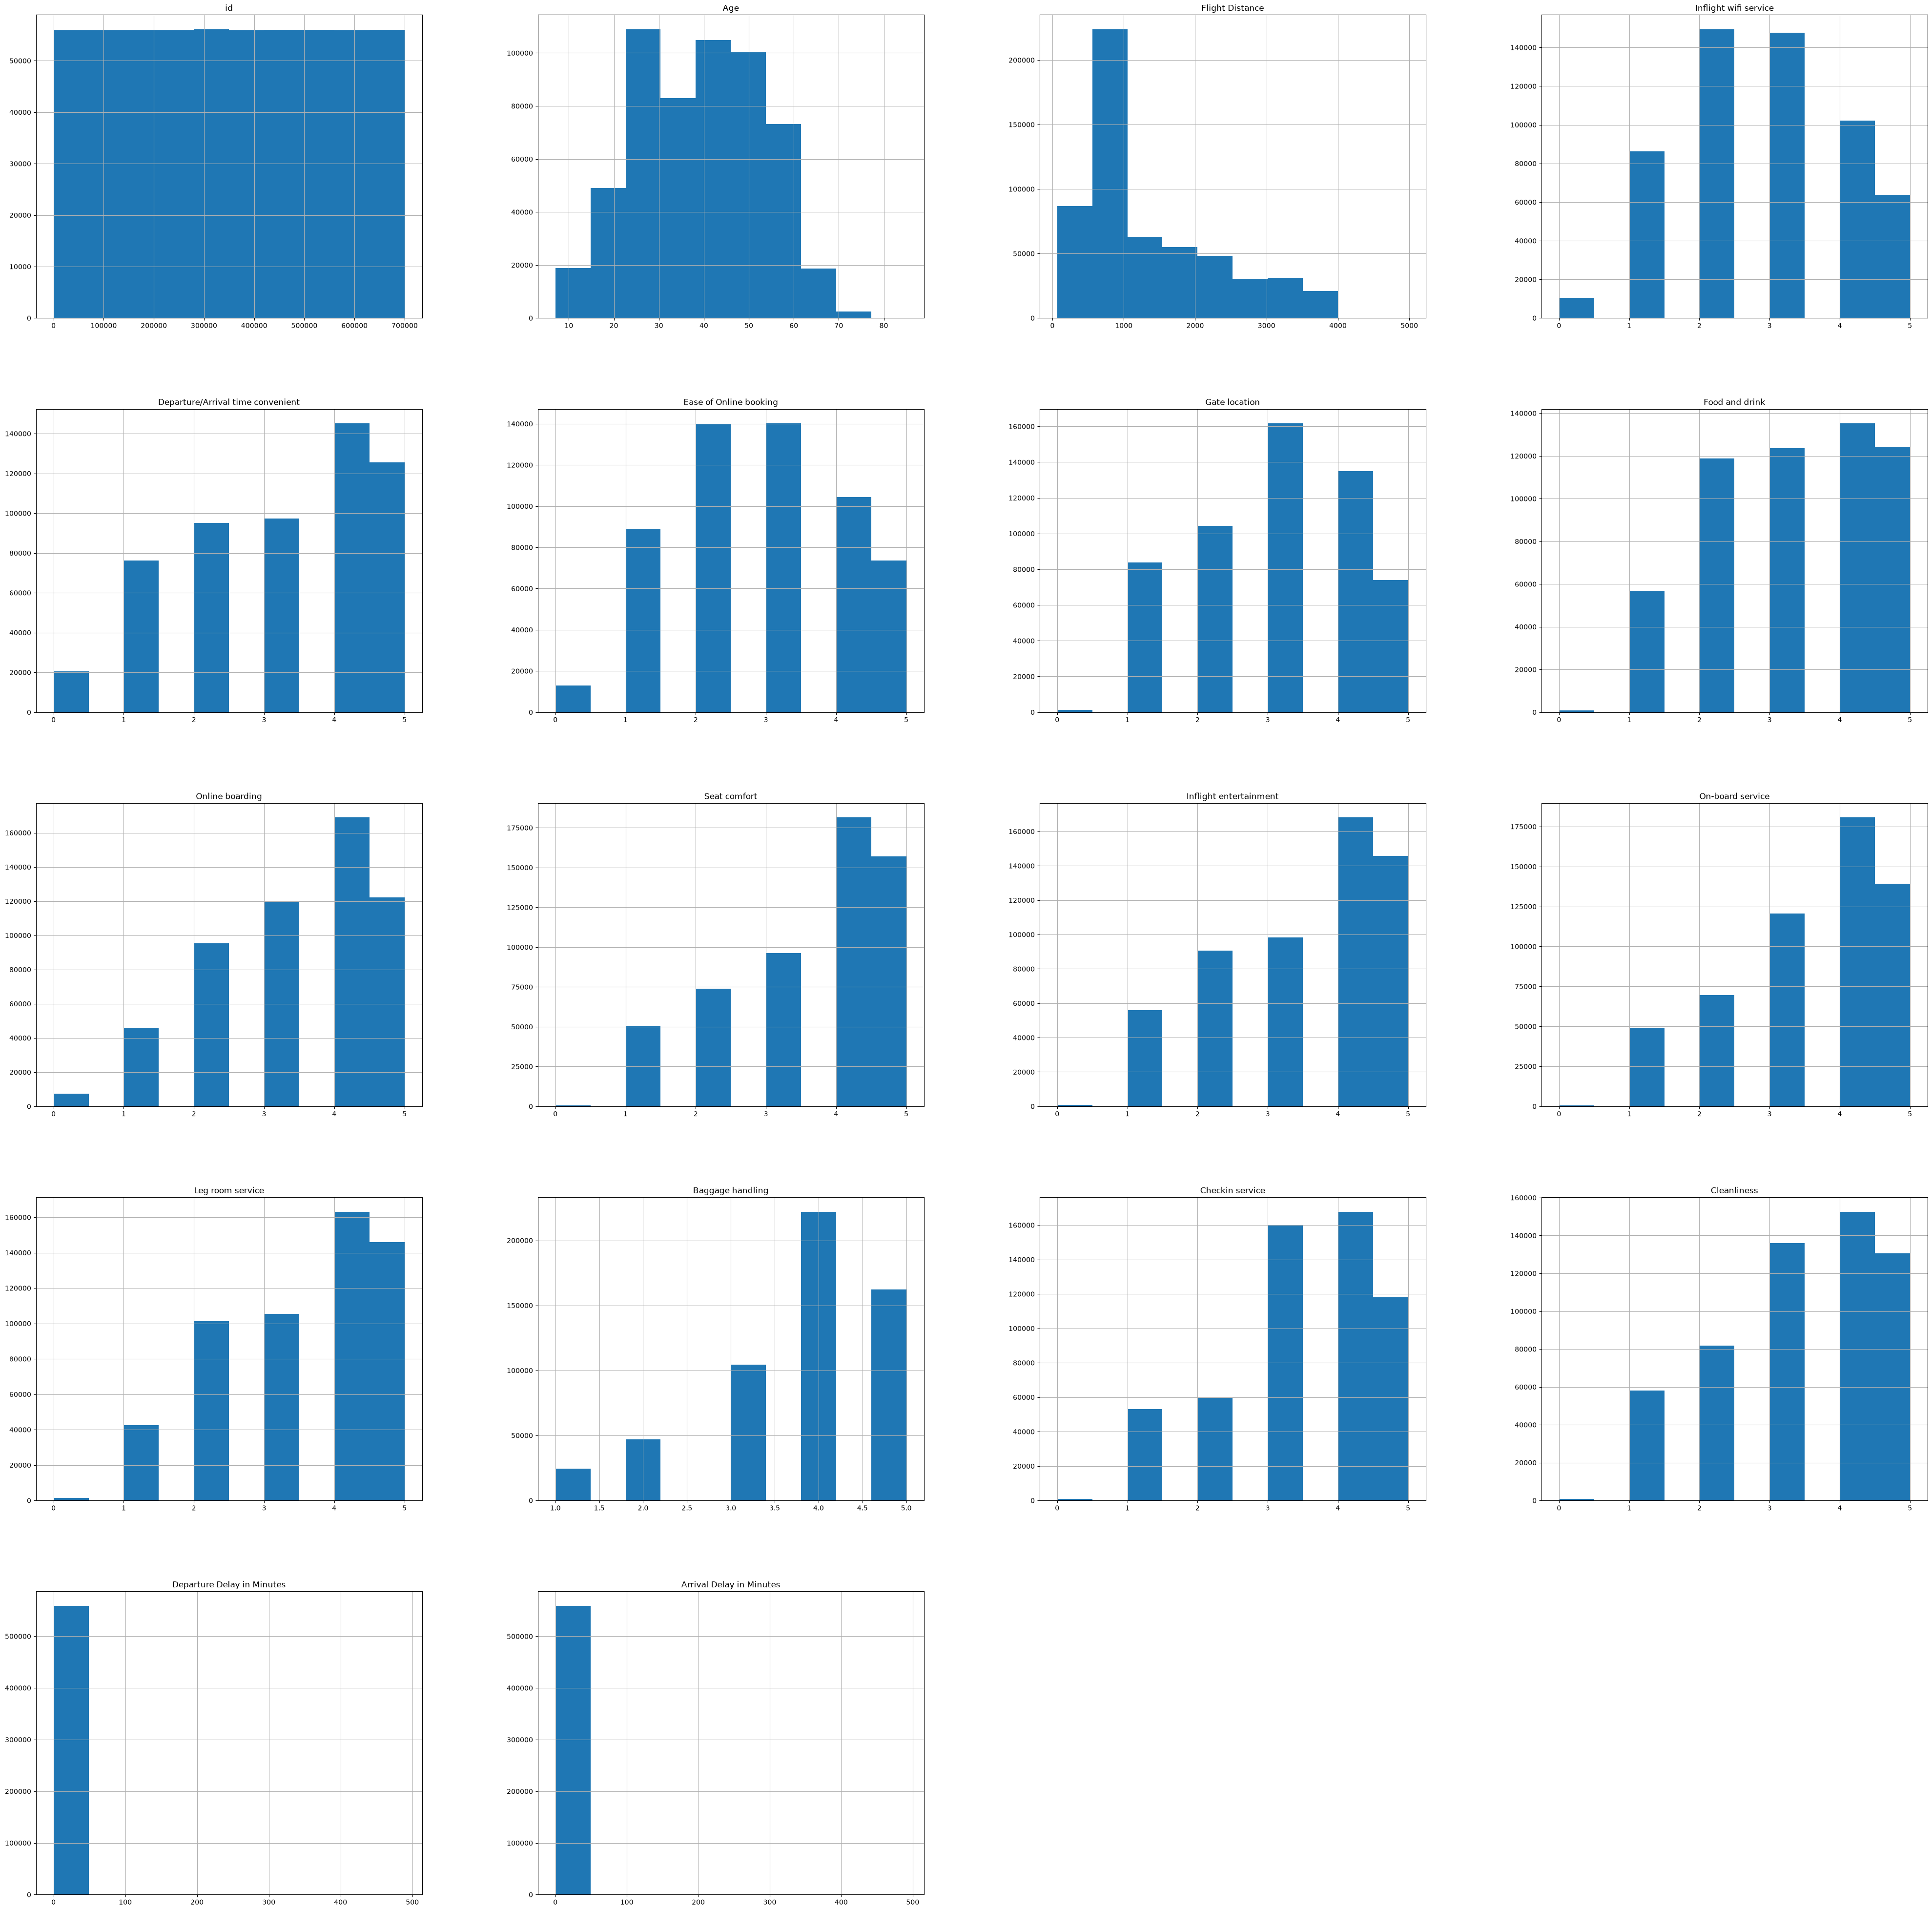

In [14]:
x_train.hist(figsize=(50,50))

In [15]:
x1 = dropper().fit_transform(x_train)
print("dropper done")

x1=AirlineFeatureEngineer().fit_transform(x1)
print("FE done")

x1 = ordinalencoder().fit_transform(x1)
print("ordinal done")

x1 = OHEEncoder().fit_transform(x1)
print("ohe done")

dropper done
FE done
ordinal done
ohe done


In [16]:
y1=y_train
y1.head()

159366    1
659958    0
434666    0
427957    1
409049    0
Name: satisfaction, dtype: int64

In [17]:
pipe1 = Pipeline([
    ('drop_cols', dropper()),
    # ('addfe', AirlineFeatureEngineer()),
    ('ordinal_encode', ordinalencoder()),
    ('one_hot_encode', OHEEncoder()),
    ('model', XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=8,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=9,
        reg_lambda=10,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])

In [47]:
param_grid = {
    'model__n_estimators': [200, 300, 400],
    'model__max_depth': [4, 6, 8],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__min_child_weight': [1, 3, 5],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__reg_alpha': [5, 9, 12],
    'model__reg_lambda': [1, 5, 10]
}
search = RandomizedSearchCV(
    estimator=pipe1,
    param_distributions=param_grid,
    n_iter=30,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

search.fit(x_train, y_train)

print("Best Parameters:")
print(search.best_params_)

print("Best ROC-AUC:")
print(search.best_score_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best Parameters:
{'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__reg_alpha': 9, 'model__n_estimators': 400, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}
Best ROC-AUC:
0.9587720457013149


In [18]:
pipe1.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('drop_cols', ...), ('ordinal_encode', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None


In [19]:
y_pred_final=pipe1.predict(x_test)
y_prob_final = pipe1.predict_proba(x_test)[:, 1]

In [20]:
y_pred_final

array([0, 1, 0, ..., 0, 1, 0], shape=(139927,))

In [21]:
y_prob_final

array([0.02265193, 0.9247199 , 0.04897617, ..., 0.0220551 , 0.95413065,
       0.04612629], shape=(139927,), dtype=float32)

In [22]:
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_final))
print("F1:", f1_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall:", recall_score(y_test, y_pred_final))

Accuracy: 0.9250394848742559
ROC-AUC: 0.9578153246731926
F1: 0.9143552351168848
Precision: 0.9269572703342549
Recall: 0.9020912547528517


In [23]:
x_test_final=pd.read_csv('test.csv')
x_test_final

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299839,999474,32,1725,3,1,3,3,3,3,3,...,3,3,1,3,0,0.0,Female,Loyal Customer,Business travel,Business
299840,999475,24,1325,3,3,3,4,3,3,3,...,2,3,5,3,0,0.0,Female,disloyal Customer,Business travel,Eco
299841,999476,33,190,4,5,4,3,3,4,3,...,3,2,2,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco
299842,999477,59,678,3,5,3,2,4,3,5,...,4,4,4,5,4,0.0,Male,Loyal Customer,Personal Travel,Eco


In [24]:
y_prob_final_test=pipe1.predict_proba(x_test_final)[:,1]

In [25]:
submission = pd.DataFrame({
    'id': range(699635, 699635 + len(y_prob_final_test)),
    'satisfaction': y_prob_final_test
})

submission.to_csv('modelresxgb.csv', index=False)

In [26]:
import joblib

joblib.dump(pipe1, "air_plane.pkl")

['air_plane.pkl']

In [27]:
import os

print(os.path.exists("air_plane.pkl"))

True


In [28]:
print(os.path.getsize("air_plane.pkl") / 1024 / 1024, "MB")

3.857729911804199 MB


In [29]:
model = joblib.load("air_plane.pkl")

pred = model.predict(x_test.iloc[:5])
prob = model.predict_proba(x_test.iloc[:5])[:, 1]

print(pred)
print(prob)

[0 1 0 1 0]
[0.02265193 0.9247199  0.04897617 0.90623885 0.09329771]


In [30]:
joblib.dump(pipe1, "air_plane.pkl")

['air_plane.pkl']

In [31]:
print(os.getcwd())

/Users/yuvrajbiswal/Downloads/airline satistfaction
